# PEFT Showdown: results analysis

Loads every result JSON in `results/final/` and produces:

- `analysis/unified_table.md` / `.csv`: all methods x tasks x regimes, plus efficiency
- `analysis/low_data_table.md`: accuracy lost going from full data to 1k examples
- `analysis/figures/*.png`: the four plots for the report

Works with any subset of methods, so it can be re-run as results arrive.
Run it from the repo root or from `analysis/`. Scores are GLUE validation, mean ± std over seeds, x100.

In [1]:
import sys  # Standard library; used to add the repo folder to Python's import search path.
from pathlib import Path  # Object-style file paths that work on Windows and Linux.

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()  # Find the repo root: if the notebook is opened from the analysis/ folder, go one level up; otherwise the current folder already is the repo root. This is what lets the notebook run from either place.
sys.path.insert(0, str(ROOT))  # Put the repo root at the front of the import search path, so "from src.results import ..." works. Without it you get "No module named src".

import matplotlib  # Plotting library (base package).
import matplotlib.pyplot as plt  # Plotting interface (subplots, bar, scatter, savefig ...), imported as plt by convention.
import numpy as np  # NumPy: maths on arrays (arange for bar positions, nan, mean of drops).
import pandas as pd  # pandas: tables. All results are loaded into one DataFrame and grouped / averaged with it.
from src.results import METHODS, TASKS, load_results  # From our results.py: METHODS and TASKS (fixed order for rows and columns) and load_results (reads all result JSONs into one table).

OUT = ROOT / "analysis"  # Folder where the tables are written (analysis/).
FIG = OUT / "figures"  # Folder where the figures are written (analysis/figures/).
FIG.mkdir(parents=True, exist_ok=True)  # Create the figures folder if it doesn't exist (parents=True also creates missing parent folders; exist_ok=True = no error if it exists). Without it, savefig would fail on a fresh checkout.

NAMES = {"full_ft": "Full FT", "lora": "LoRA", "adapter": "Adapters",  # Readable display names for tables and plots, instead of code names like "full_ft" ...
         "prompt_tuning": "Prompt tuning"}  # ... (continued).
TASK_NAMES = {"sst2": "SST-2", "mrpc": "MRPC", "rte": "RTE"}  # Readable task names for column headers and plot titles.
REGIMES = ["full", "1k"]  # The two data regimes, in the order used for columns and bars: full data first, then 1k examples.
COLORS = dict(zip(METHODS, plt.get_cmap("tab10").colors))  # One fixed colour per method from matplotlib's "tab10" palette, so a method has the SAME colour in every plot.
EXPECTED_RUNS = 16  # per method, see issue #25 -- each method should have 16 final runs (RTE/MRPC full and 1k x 3 seeds, SST-2 1k x 3, SST-2 full x 1). Used by the run-count check below.

df = load_results("final", root=ROOT / "results")  # Load every final result JSON (results/final/*.json) into one table: one row per run, columns like "metrics.accuracy".
methods = [m for m in METHODS if m in set(df["method"])]  # Methods that actually have results, kept in the standard METHODS order. Lets the notebook work even if some methods haven't finished yet.
print(f"{len(df)} runs, methods: {[NAMES[m] for m in methods]}")  # Print how many runs were loaded and for which methods: a quick check that everything was found.

32 runs, methods: ['Full FT', 'LoRA']


## Run counts
Each method should have 16 runs: RTE/MRPC full and 1k x 3 seeds, SST-2 1k x 3 seeds, SST-2 full x 1 seed.

In [2]:
counts = (df.groupby(["method", "task", "regime"]).size()  # Count the runs per method, task and regime: groupby(...).size() counts rows in each group ...
            .unstack(["task", "regime"]).reindex(methods).fillna(0).astype(int))  # ... unstack turns task/regime into columns (one row per method); reindex puts methods in the standard order; fillna(0) turns missing combinations into 0; astype(int) shows whole numbers.
counts["total"] = counts.sum(axis=1)  # Add a "total" column: the sum of each method's row.
for m, n in counts["total"].items():  # For each method and its total number of runs:
    if n != EXPECTED_RUNS:  # if it is not exactly 16 ...
        print(f"WARNING: {NAMES[m]} has {n} runs, expected {EXPECTED_RUNS}")  # ... print a warning, so missing or duplicate runs are noticed BEFORE the tables are trusted.
counts  # Show the count table as the cell's output (the last expression in a cell is displayed).

C:\Users\hp\AppData\Local\Temp\ipykernel_17592\2050680974.py:3: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  counts["total"] = counts.sum(axis=1)


task    mrpc      rte      sst2      total
regime    1k full  1k full   1k full      
method                                    
full_ft    3    3   3    3    3    1    16
lora       3    3   3    3    3    1    16

## Unified table

In [3]:
def mean_std(s):  # HELPER mean_std: turns a column of scores (fractions like 0.761) into the text "mean ± std" in percent, e.g. "76.1 ± 2.2".
    s = s.dropna() * 100  # Drop missing values and convert fractions to percent.
    if len(s) == 0:  # No values at all ...
        return "–"  # ... show a dash instead of "nan".
    if len(s) == 1:  # Only one value (e.g. SST-2 full, which has only seed 1) ...
        return f"{s.iloc[0]:.1f}"  # ... show just that value; the std of one value is undefined.
    return f"{s.mean():.1f} ± {s.std(ddof=1):.1f}"  # Otherwise mean ± SAMPLE standard deviation (ddof=1 divides by n-1, correct for a small sample like 3 seeds), 1 decimal each.


def num(s, fmt):  # HELPER num: formats one number, or the mean of a column, with the given format (e.g. ".0f" = no decimals). Used for memory and time.
    if np.isscalar(s):  # If s is a single number ...
        return "–" if pd.isna(s) else format(s, fmt)  # ... return a dash if it is missing (NaN), otherwise the formatted number.
    s = s.dropna()  # Otherwise s is a column: drop missing values ...
    return format(s.mean(), fmt) if len(s) else "–"  # ... and format its mean, or a dash if nothing is left.


rows = []  # List of table rows, one dict per method.
for m in methods:  # For each method that has results:
    d = df[df["method"] == m]  # keep only this method's runs.
    row = {"Method": NAMES[m]}  # Start the row with the method's display name.
    for t in TASKS:  # For each task (SST-2, MRPC, RTE) ...
        for r in REGIMES:  # ... and each regime (full, 1k):
            x = d[(d["task"] == t) & (d["regime"] == r)]  # the runs of this task and regime (e.g. 3 seeds).
            label = f"{TASK_NAMES[t]} {r}"  # Column name, e.g. "RTE 1k".
            row[f"{label} acc"] = mean_std(x["metrics.accuracy"])  # Accuracy column, e.g. "RTE 1k acc" = "69.9 ± 2.1".
            if t == "mrpc":  # MRPC only ...
                row[f"{label} F1"] = mean_std(x["metrics.f1"])  # ... also an F1 column, because F1 is MRPC's official GLUE metric.
    eff = lambda c: d[c].dropna()  # Small helper: the values of column c for this method, without missing values.
    row["Trainable params"] = f"{int(eff('efficiency.trainable_params').median()):,}"  # Trainable parameters: the same in every run of a method, so the median simply picks that value; shown with thousands separators.
    row["% trainable"] = f"{eff('efficiency.trainable_pct').median():.2f}"  # Percentage of parameters trained, 2 decimals.
    row["Peak mem (MiB)"] = num(eff("efficiency.peak_gpu_mem_mb").max(), ".0f")  # Peak GPU memory: the MAXIMUM over all of this method's runs (the worst case is what decides whether it fits on a GPU).
    for t in ("rte", "sst2"):  # Training time is shown for two tasks:
        x = d[(d["task"] == t) & (d["regime"] == "full")]["efficiency.train_time_s"]  # the full-data runs of that task ...
        row[f"Time {TASK_NAMES[t]} full (s)"] = num(x, ".0f")  # ... their mean training time in whole seconds, e.g. "Time RTE full (s)".
    row["Checkpoint (MB)"] = f"{eff('efficiency.checkpoint_size_mb').median():.1f}"  # Checkpoint size on disk (MB), the same for every run of a method; median picks it.
    rows.append(row)  # Add the finished row to the list.

unified = pd.DataFrame(rows).set_index("Method")  # Turn the rows into a table with the method names as row labels. This is THE unified comparison table the project brief asks for.
unified.to_csv(OUT / "unified_table.csv")  # Save it as CSV (for spreadsheets).
(OUT / "unified_table.md").write_text(  # Save it as Markdown for the report, starting with ...
    "Scores: GLUE validation, x100, mean ± std over seeds 1-3 "  # ... a caption explaining the numbers: validation scores x100, mean ± std over 3 seeds ...
    "(SST-2 full: seed 1 only). Peak memory: max over all runs. "  # ... how memory is aggregated ...
    "Times: Tesla T4, fp16, batch 32.\n\n"  # ... and the hardware / settings ...
    + unified.to_markdown() + "\n", encoding="utf-8")  # ... followed by the table itself in Markdown format.
unified.T  # Show the table TRANSPOSED (methods as columns), which is easier to read in the notebook because there are many columns.

Method,Full FT,LoRA
SST-2 full acc,94.0,93.7
SST-2 1k acc,90.4 ± 0.5,90.1 ± 0.5
MRPC full acc,87.7 ± 1.4,87.1 ± 1.0
MRPC full F1,91.2 ± 1.2,90.9 ± 0.6
MRPC 1k acc,85.8 ± 2.2,84.3 ± 1.3
MRPC 1k F1,89.9 ± 1.4,88.8 ± 0.9
RTE full acc,76.1 ± 2.2,74.0 ± 2.0
RTE 1k acc,69.9 ± 2.1,66.9 ± 3.2
Trainable params,"124,647,170","887,042"
% trainable,100.00,0.71


## Numeric summary
Means and standard deviations per method, task and regime (used by the plots).

In [4]:
cols = ["metrics.accuracy", "metrics.f1", "efficiency.peak_gpu_mem_mb",  # The numeric columns to summarise: accuracy, F1, peak memory ...
        "efficiency.train_time_s"]  # ... and training time.
summary = df.groupby(["method", "task", "regime"])[cols].agg(["mean", "std", "count"])  # For every method / task / regime combination, compute the mean, standard deviation and number of runs of each column. These raw numbers back the plots.
summary.to_csv(OUT / "summary_numeric.csv")  # Save them as analysis/summary_numeric.csv.
summary  # Show the summary table as the cell's output.

metrics.accuracy                 metrics.f1            \
                                mean       std count       mean       std   
method  task regime                                                         
full_ft mrpc 1k             0.857843  0.022464     3   0.898677  0.013835   
             full           0.877451  0.013646     3   0.912112  0.011668   
        rte  1k             0.699158  0.020528     3        NaN       NaN   
             full           0.760529  0.022058     3        NaN       NaN   
        sst2 1k             0.903670  0.005255     3        NaN       NaN   
             full           0.940367       NaN     1        NaN       NaN   
lora    mrpc 1k             0.843137  0.012969     3   0.887962  0.009008   
             full           0.870915  0.009906     3   0.909459  0.005566   
        rte  1k             0.669073  0.031541     3        NaN       NaN   
             full           0.740072  0.020100     3        NaN       NaN   
        sst2 1k             0.900612  0.004635     3        NaN       NaN   
             full           0.936927       NaN     1        NaN       NaN   

                          efficiency.peak_gpu_mem_mb                   \
                    count                       mean        std count   
method  task regime                                                     
full_ft mrpc 1k         3                2918.700000  77.507354     3   
             full       3                2973.100000   9.591142     3   
        rte  1k         0                3264.400000   0.000000     3   
             full       0                3264.400000   0.000000     3   
        sst2 1k         0                2401.633333  29.338428     3   
             full       0                2487.300000        NaN     1   
lora    mrpc 1k         3                1685.533333  67.945591     3   
             full       3                1721.600000   2.163331     3   
        rte  1k         0                1937.200000   0.000000     3   
             full       0                1937.200000   0.000000     3   
        sst2 1k         0                1260.133333  25.058798     3   
             full       0                1331.700000        NaN     1   

                    efficiency.train_time_s                  
                                       mean       std count  
method  task regime                                          
full_ft mrpc 1k                  149.233333  6.924112     3  
             full                162.700000  1.539480     3  
        rte  1k                  167.533333  5.415102     3  
             full                158.133333  0.057735     3  
        sst2 1k                  185.400000  3.593049     3  
             full                491.800000       NaN     1  
lora    mrpc 1k                   77.333333  0.757188     3  
             full                111.933333  0.057735     3  
        rte  1k                  110.366667  6.803920     3  
             full                112.300000  0.200000     3  
        sst2 1k                  132.966667  0.550757     3  
             full                324.300000       NaN     1

## Low-data regime
Accuracy points lost when training on 1k examples instead of the full training set. Smaller is better.

In [5]:
acc = df.groupby(["method", "task", "regime"])["metrics.accuracy"].mean().mul(100)  # Mean validation accuracy for every (method, task, regime), converted to percent. Indexed by those three keys, so acc[(m, t, r)] gives one number.
low_rows = []  # List of table rows, one per method.
for m in methods:  # For each method:
    row = {"Method": NAMES[m]}  # start the row with its display name.
    drops = []  # Collect the accuracy drops of each task, to average them at the end.
    for t in TASKS:  # For each task:
        try:  # try to read both numbers ...
            full, few = acc[(m, t, "full")], acc[(m, t, "1k")]  # ... full-data accuracy and 1k accuracy for this method and task.
        except KeyError:  # If either is missing (run not done yet) ...
            row[TASK_NAMES[t]] = "–"  # ... show a dash in this cell ...
            continue  # ... and skip to the next task.
        drops.append(full - few)  # Accuracy LOST by using only 1,000 examples (positive = worse with less data).
        row[TASK_NAMES[t]] = f"{full:.1f} → {few:.1f} ({few - full:+.1f})"  # Cell text, e.g. "76.1 → 69.9 (-6.1)"; "+.1f" always shows the sign.
    row["Mean drop"] = f"{np.mean(drops):.1f}" if drops else "–"  # Average drop over the tasks, or a dash if no task had both numbers. Smaller = the method copes better with little data.
    low_rows.append(row)  # Add the row.
low = pd.DataFrame(low_rows).set_index("Method")  # Build the table with method names as row labels.
(OUT / "low_data_table.md").write_text(  # Save it as analysis/low_data_table.md, starting with ...
    "Validation accuracy x100, full data → 1k examples (change). Mean over seeds.\n\n"  # ... a caption that explains the numbers ...
    + low.to_markdown() + "\n", encoding="utf-8")  # ... followed by the table in Markdown.
low  # Show the table as the cell's output.

,SST-2,MRPC,RTE,Mean drop
Method,,,,
Full FT,94.0 → 90.4 (-3.7),87.7 → 85.8 (-2.0),76.1 → 69.9 (-6.1),3.9
LoRA,93.7 → 90.1 (-3.6),87.1 → 84.3 (-2.8),74.0 → 66.9 (-7.1),4.5


## Plot 1: accuracy vs trainable parameters (full data)

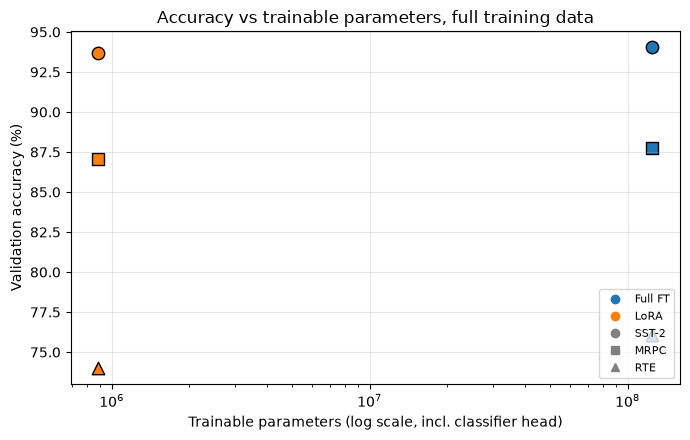

In [6]:
markers = {"sst2": "o", "mrpc": "s", "rte": "^"}  # Marker shape per task: circle = SST-2, square = MRPC, triangle = RTE. Colour = method, shape = task.
fig, ax = plt.subplots(figsize=(7, 4.5))  # Create one plot, 7 x 4.5 inches.
for m in methods:  # For each method ...
    for t in TASKS:  # ... and each task:
        x = df[(df["method"] == m) & (df["task"] == t) & (df["regime"] == "full")]  # this method's FULL-data runs on this task.
        if x.empty:  # If there are none ...
            continue  # ... skip (nothing to plot).
        ax.scatter(x["efficiency.trainable_params"].median(),  # Draw one point: x = number of trainable parameters ...
                   x["metrics.accuracy"].mean() * 100,  # ... y = mean validation accuracy in percent ...
                   color=COLORS[m], marker=markers[t], s=80, edgecolor="black")  # ... in the method's colour and the task's marker shape, size 80, black outline so overlapping points stay visible.
ax.set_xscale("log")  # Logarithmic x-axis: trainable parameters range from 0.6 million to 125 million; on a normal axis the PEFT methods would all be squashed against the left edge.
ax.set_xlabel("Trainable parameters (log scale, incl. classifier head)")  # X-axis label (the classifier head is included in every count, so methods are comparable).
ax.set_ylabel("Validation accuracy (%)")  # Y-axis label.
ax.set_title("Accuracy vs trainable parameters, full training data")  # Plot title. The message of this plot: PEFT methods reach almost the same accuracy with about 100x fewer trained parameters.
method_handles = [plt.Line2D([], [], marker="o", ls="", color=COLORS[m], label=NAMES[m])  # Legend entries for the colours: one invisible line with a dot per method (ls="" = no line) ...
                  for m in methods]  # ... (continued).
task_handles = [plt.Line2D([], [], marker=markers[t], ls="", color="gray",  # Legend entries for the shapes: one grey marker per task ...
                           label=TASK_NAMES[t]) for t in TASKS]  # ... (continued).
ax.legend(handles=method_handles + task_handles, fontsize=8, loc="lower right")  # Show both legend groups together, small font, in the lower-right corner.
ax.grid(alpha=0.3)  # Light grid lines to make values easier to read.
fig.tight_layout()  # Adjust spacing so labels don't overlap.
fig.savefig(FIG / "acc_vs_params.png", dpi=150)  # Save the plot as analysis/figures/acc_vs_params.png at 150 dpi (used in the report).
plt.show()  # Display the plot in the notebook.

## Plot 2: full data vs 1k examples

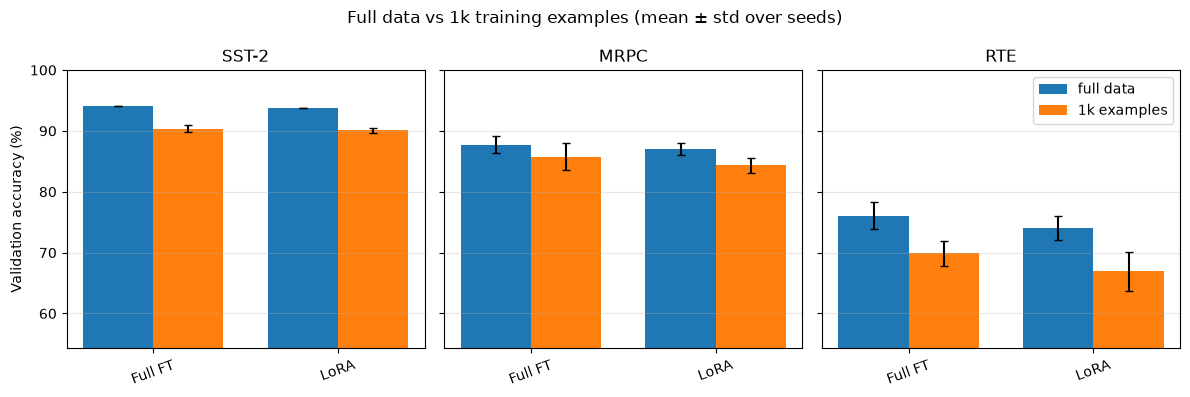

In [7]:
fig, axes = plt.subplots(1, len(TASKS), figsize=(12, 4), sharey=True)  # One plot per task, side by side, 12 x 4 inches; sharey=True gives all three the same y-axis scale so they can be compared.
width = 0.38  # Width of each bar; two bars (full and 1k) per method fit in the space of 1.
for ax, t in zip(axes, TASKS):  # For each task, with its own plot area:
    xs = np.arange(len(methods))  # x positions of the method groups: 0, 1, 2, 3.
    for k, r in enumerate(REGIMES):  # For each regime (k = 0 for full, 1 for 1k):
        means, stds = [], []  # lists for the bar heights and error bars.
        for m in methods:  # For each method:
            s = df[(df["method"] == m) & (df["task"] == t) & (df["regime"] == r)]["metrics.accuracy"] * 100  # the validation accuracies (percent) of this method, task and regime.
            means.append(s.mean() if len(s) else np.nan)  # Bar height = mean accuracy (NaN if there are no runs, which leaves a gap).
            stds.append(s.std(ddof=1) if len(s) > 1 else 0)  # Error bar = sample std over seeds; 0 if only one run (SST-2 full), because the std of one value is undefined.
        ax.bar(xs + (k - 0.5) * width, means, width, yerr=stds, capsize=3,  # Draw the bars, shifted half a bar left (full) or right (1k) of each method's position, with error bars ...
               label="full data" if r == "full" else "1k examples",  # ... legend label for this regime ...
               color="tab:blue" if r == "full" else "tab:orange")  # ... blue for full data, orange for 1k examples.
    ax.set_xticks(xs, [NAMES[m] for m in methods], rotation=20)  # Method names under the bar groups, rotated 20 degrees so they don't overlap.
    ax.set_title(TASK_NAMES[t])  # Plot title = task name.
    ax.grid(axis="y", alpha=0.3)  # Horizontal grid lines only.
axes[0].set_ylabel("Validation accuracy (%)")  # Y-axis label, only on the first plot (the y-axis is shared).
lo = np.nanmin(df["metrics.accuracy"]) * 100  # The lowest accuracy over all runs, in percent ...
axes[0].set_ylim(max(0, lo - 10), 100)  # ... start the y-axis 10 points below it (but not below 0), so the differences between bars are visible instead of all bars looking the same height.
axes[-1].legend()  # Legend only on the last plot, to avoid repeating it three times.
fig.suptitle("Full data vs 1k training examples (mean ± std over seeds)")  # Title for the whole figure.
fig.tight_layout()  # Adjust spacing.
fig.savefig(FIG / "full_vs_1k.png", dpi=150)  # Save as analysis/figures/full_vs_1k.png at 150 dpi.
plt.show()  # Display the figure.

## Plots 3 and 4: peak GPU memory and training time (full data)

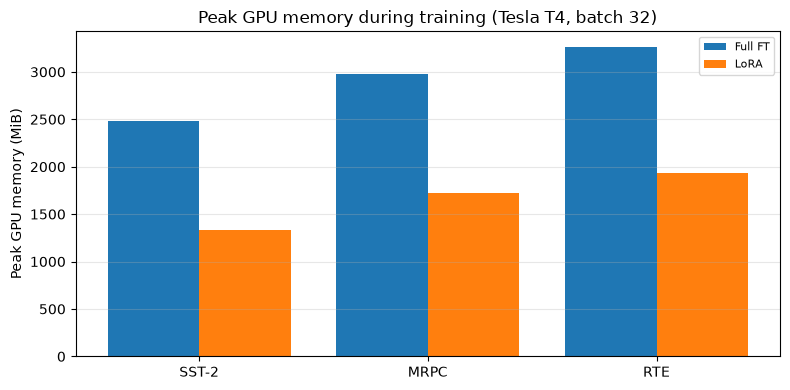

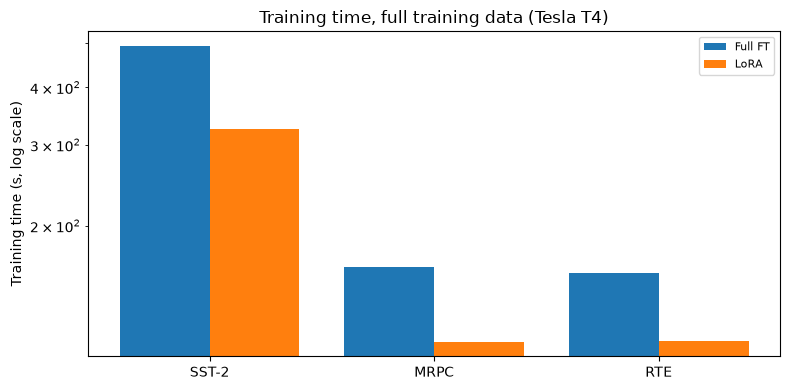

In [8]:
def grouped_bar(col, ylabel, title, fname, log=False):  # HELPER grouped_bar: draws a grouped bar chart of one efficiency column (memory or time): one group of bars per task, one bar per method. Written once and used twice below.
    fig, ax = plt.subplots(figsize=(8, 4))  # Create one plot, 8 x 4 inches.
    width = 0.8 / max(len(methods), 1)  # Bar width: the methods share 80% of each group's space (max(...,1) avoids dividing by zero if no method has results).
    xs = np.arange(len(TASKS))  # x positions of the task groups: 0, 1, 2.
    for k, m in enumerate(methods):  # For each method (k = its position in the group):
        vals = [df[(df["method"] == m) & (df["task"] == t) & (df["regime"] == "full")][col].mean()  # its mean value of the column on FULL data, for each task ...
                for t in TASKS]  # ... (continued).
        ax.bar(xs + (k - (len(methods) - 1) / 2) * width, vals, width,  # Draw its bars, shifted so the methods sit side by side centred on each task position ...
               label=NAMES[m], color=COLORS[m])  # ... labelled and coloured by method.
    ax.set_xticks(xs, [TASK_NAMES[t] for t in TASKS])  # Task names under the groups.
    ax.set_ylabel(ylabel)  # Y-axis label (given by the caller).
    ax.set_title(title)  # Plot title (given by the caller).
    if log:  # If a log scale was requested ...
        ax.set_yscale("log")  # ... use a logarithmic y-axis (training times range from about 100 s to 500 s across tasks, so small bars stay readable).
    ax.grid(axis="y", alpha=0.3)  # Horizontal grid lines only.
    ax.legend(fontsize=8)  # Legend with the method names, small font.
    fig.tight_layout()  # Adjust spacing.
    fig.savefig(FIG / fname, dpi=150)  # Save the figure under the given file name in analysis/figures/.
    plt.show()  # Display it.


grouped_bar("efficiency.peak_gpu_mem_mb", "Peak GPU memory (MiB)",  # Plot 3: peak GPU memory per method and task. Shows PEFT methods using about 40% less memory than full FT ...
            "Peak GPU memory during training (Tesla T4, batch 32)", "peak_memory.png")  # ... title and file name for this plot.
grouped_bar("efficiency.train_time_s", "Training time (s, log scale)",  # Plot 4: training time per method and task, on a log scale ...
            "Training time, full training data (Tesla T4)", "train_time.png", log=True)  # ... title, file name, and log=True.